# Figure 3 and Extended Data Figure 3: Simplex dynamics

Run from this directory. Saved fields are used by default; set `RECOMPUTE=True` to regenerate them. Dependencies: NumPy, pandas, SciPy, Matplotlib, and Numba.

Reputations equilibrate from all-good initial conditions under continuous relaxation. Every saved field and equilibrium must pass the reputation residual criterion. The model, payoffs, and plotting geometry are unchanged. No basin shading is added.

In [1]:
from dataclasses import dataclass, asdict
from pathlib import Path
from time import perf_counter
from typing import Dict, List, Tuple
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from numba import njit, prange, set_num_threads, get_num_threads
from scipy.optimize import brentq, minimize_scalar, root

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'simplex_dynamics'
FIGURE3 = ROOT / 'figures' / 'figure3'
ED3 = ROOT / 'figures' / 'ed3_simplex'
for directory in (DATA, FIGURE3, ED3):
    directory.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False
set_num_threads(min(4, get_num_threads()))
NORMS = ('SC', 'SH', 'SJ', 'SS')
NORM_PARAMETERS = {'SC': (1., 0.), 'SH': (0., 0.), 'SJ': (0., 1.), 'SS': (1., 1.)}
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning', 'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
DEPTHS = {'SC': (2, 0), 'SH': (3, 0), 'SJ': (4, 3), 'SS': (1, 2)}
EQUILIBRIUM_COLORS = {0: '#6B6B6B', 1: '#0077BB', 2: '#D55E00'}
COLOR_STREAM, COLOR_BOUNDARY = '#666666', '#2F2F2F'
SQRT3 = np.sqrt(3.)
HEIGHT = SQRT3 / 2
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8,
                     'pdf.fonttype': 42, 'svg.fonttype': 'none'})

@dataclass(frozen=True)
class Parameters:
    norm: str = 'SC'
    b: float = 5.0
    c: float = 1.0
    e1: float = 0.02
    e2: float = 0.02
    alpha: float = 0.0
    beta: float = 0.0
    k1: int = 1
    k2: int = 1

    def __post_init__(self):
        if self.norm not in NORM_PARAMETERS:
            raise ValueError(f'Unknown norm: {self.norm}')
        if self.c <= 0 or self.b <= 0:
            raise ValueError('b and c must be positive.')
        if not (0 <= self.e1 <= 1 and 0 <= self.e2 <= 1):
            raise ValueError('e1 and e2 must lie in [0,1].')
        if not (0 <= self.alpha <= 1 and 0 <= self.beta <= 1):
            raise ValueError('alpha and beta must lie in [0,1].')
        if int(self.k1) != self.k1 or int(self.k2) != self.k2:
            raise ValueError('k1 and k2 must be integers.')
        if self.k1 < 0 or self.k2 < 0:
            raise ValueError('k1 and k2 must be non-negative.')

@dataclass(frozen=True)
class PlotSettings:
    grid_nx: int = 84
    grid_ny: int = 74
    stream_seed_depth: int = 20
    edge_scan_points: int = 301
    interior_seed_depth: int = 7
    edge_interior_merge_tolerance: float = 0.02
    reputation_tolerance: float = 1e-12
    legacy_max_iter: int = 1000
    show_equilibria: bool = True
    show_legend: bool = False
    show_parameter_title: bool = False

SETTINGS = PlotSettings(grid_nx=84, grid_ny=74, stream_seed_depth=20,
    edge_scan_points=501, interior_seed_depth=7, reputation_tolerance=1e-12)
CASE_DEFINITIONS = (
    ('without_inertia', 0., 0.), ('one_step', 1., 1.), ('multi_step', 1., 1.),
    ('tolerance_only', 1., 0.), ('strictness_only', 0., 1.))
CASES = []
for regime, alpha, beta in CASE_DEFINITIONS:
    for norm in NORMS:
        k1, k2 = DEPTHS[norm] if regime == 'multi_step' else (1, 1)
        CASES.append(dict(case=f'{regime}_{norm}', regime=regime,
            parameters=asdict(Parameters(norm=norm, alpha=alpha, beta=beta, k1=k1, k2=k2))))
CONFIG = {'cases': CASES, 'plot_settings': asdict(SETTINGS),
          'reputation_equation': 'dr/dtau = R(phi) - r', 'initial_reputations': [1., 1., 1.],
          'rk4_stages': [{'dt': .1, 'max_steps': 20000}, {'dt': .2, 'max_steps': 80000}, {'dt': .2, 'max_steps': 200000}],
          'legacy_equation': 'synchronous mean and squared-mean iteration',
          'edge_markers': 'tangent stability; transverse eigenvalues saved separately'}


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


## Reputation and strategy equations

The synchronous iteration is retained only to quantify differences from the earlier numerical method. The plotted fields use the continuous reputation equation.

In [2]:
def geometric_sum(x, n: int):
    """Closed form for sum_{i=1}^n x^i; supports NumPy arrays."""
    x = np.asarray(x, dtype=float)
    if n <= 0:
        return np.zeros_like(x)
    out = np.empty_like(x)
    near_one = np.abs(1.0 - x) < 1e-12
    out[near_one] = float(n)
    regular = ~near_one
    out[regular] = x[regular] * (1.0 - x[regular] ** n) / (1.0 - x[regular])
    return out

def reputation_transform(p, par: Parameters):
    """Independent k1-k2 mapping"""
    p = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
    left_power = np.ones_like(p) if par.k1 == 0 else (1.0 - p) ** par.k1
    right_power = np.ones_like(p) if par.k2 == 0 else p ** par.k2
    denominator = left_power + right_power - left_power * right_power
    warning = geometric_sum(par.alpha * (1.0 - p), par.k1)
    suspicious = geometric_sum(p, par.k2) - geometric_sum(par.beta * p, par.k2)
    numerator = p ** (par.k2 + 1) * (1.0 + warning) + (1.0 - p) ** (par.k1 + 1) * suspicious
    result = np.divide(numerator, denominator, out=np.full_like(numerator, np.nan), where=np.abs(denominator) > 1e-15)
    return np.clip(result, 0.0, 1.0)

def assessment_probabilities(par: Parameters) -> Tuple[float, float, float, float]:
    p1, q1 = NORM_PARAMETERS[par.norm]
    epsilon = (1.0 - par.e1) * (1.0 - par.e2) + par.e1 * par.e2
    p_gc = epsilon
    p_bc = p1 * (epsilon - par.e2) + q1 * (1.0 - epsilon - par.e2) + par.e2
    p_gd = par.e2
    p_bd = q1 * (1.0 - 2.0 * par.e2) + par.e2
    return (p_gc, p_bc, p_gd, p_bd)

@njit(cache=False)
def transform(u, alpha,beta,k1,k2):
    u=min(1.,max(0.,u));v=1-u
    if alpha==0. and beta==0.:return u
    left=v**k1;right=u**k2;den=left+right-left*right
    warning=0.
    for m in range(1,k1+1):warning+=(alpha*v)**m
    suspicious=0.
    for n in range(1,k2+1):suspicious+=u**n*(1-beta**n)
    return (u**(k2+1)*(1+warning)+v**(k1+1)*suspicious)/den

@njit(cache=False)
def rhs(rc,rd,rr,fc,fd,fr,acg,acb,adg,adb,alpha,beta,k1,k2):
    g=fc*rc+fd*rd+fr*rr;g2=fc*rc*rc+fd*rd*rd+fr*rr*rr
    uc=g*acg+(1-g)*acb;ud=g*adg+(1-g)*adb
    ur=g2*acg+(g-g2)*(acb+adg)+(1-2*g+g2)*adb
    return (transform(uc,alpha,beta,k1,k2)-rc,transform(ud,alpha,beta,k1,k2)-rd,transform(ur,alpha,beta,k1,k2)-rr)

@njit(cache=False,parallel=True)
def continuous_batch(f,terms,alpha,beta,k1,k2,tol=1e-10):
    out=np.empty_like(f); residuals=np.empty(len(f));steps=np.zeros(len(f),np.int64)
    for i in prange(len(f)):
        fc,fd,fr=f[i];rc=rd=rr=1.;step=0
        for stage in range(3):
            dt=.1 if stage==0 else .2;limit=20000 if stage==0 else 80000 if stage==1 else 200000
            for j in range(limit):
                a=rhs(rc,rd,rr,fc,fd,fr,terms[0],terms[1],terms[2],terms[3],alpha,beta,k1,k2)
                err=max(abs(a[0]),abs(a[1]),abs(a[2]))
                if err<=tol:break
                b=rhs(rc+.5*dt*a[0],rd+.5*dt*a[1],rr+.5*dt*a[2],fc,fd,fr,terms[0],terms[1],terms[2],terms[3],alpha,beta,k1,k2)
                c=rhs(rc+.5*dt*b[0],rd+.5*dt*b[1],rr+.5*dt*b[2],fc,fd,fr,terms[0],terms[1],terms[2],terms[3],alpha,beta,k1,k2)
                d=rhs(rc+dt*c[0],rd+dt*c[1],rr+dt*c[2],fc,fd,fr,terms[0],terms[1],terms[2],terms[3],alpha,beta,k1,k2)
                rc=min(1.,max(0.,rc+dt*(a[0]+2*b[0]+2*c[0]+d[0])/6))
                rd=min(1.,max(0.,rd+dt*(a[1]+2*b[1]+2*c[1]+d[1])/6))
                rr=min(1.,max(0.,rr+dt*(a[2]+2*b[2]+2*c[2]+d[2])/6))
                step+=1
            if err<=tol:break
        a=rhs(rc,rd,rr,fc,fd,fr,terms[0],terms[1],terms[2],terms[3],alpha,beta,k1,k2)
        out[i]=rc,rd,rr;residuals[i]=max(abs(a[0]),abs(a[1]),abs(a[2]));steps[i]=step
    return out,residuals,steps



def legacy_reputation_batch(frequencies, par: Parameters, tolerance=1e-10, max_iter=1000):
    """Synchronous all-good iteration for many population states simultaneously."""
    f = np.atleast_2d(np.asarray(frequencies, dtype=float))
    p_gc, p_bc, p_gd, p_bd = assessment_probabilities(par)
    g = np.ones(len(f))
    g2 = np.ones(len(f))
    residual = np.full(len(f), np.inf)
    for iteration in range(1, max_iter + 1):
        p_c = g * p_gc + (1.0 - g) * p_bc
        p_d = g * p_gd + (1.0 - g) * p_bd
        p_r = g2 * p_gc + (1.0 - 2.0 * g + g2) * p_bd + (g - g2) * (p_bc + p_gd)
        reputations = np.column_stack((reputation_transform(p_c, par), reputation_transform(p_d, par), reputation_transform(p_r, par)))
        g_new = np.sum(f * reputations, axis=1)
        g2_new = np.sum(f * reputations ** 2, axis=1)
        residual = np.abs(g_new - g) + np.abs(g2_new - g2)
        if np.nanmax(residual) < tolerance:
            break
        g, g2 = (g_new, g2_new)
    converged = residual < tolerance
    return (reputations, g, converged, iteration, residual)

def reputation_equilibria_batch(frequencies, par, tolerance=1e-12):
    f = np.atleast_2d(np.asarray(frequencies, dtype=float))
    reputations, residual, steps = continuous_batch(f, np.array(assessment_probabilities(par)),
        par.alpha, par.beta, par.k1, par.k2, tolerance)
    if not np.isfinite(reputations).all() or not np.all(residual <= tolerance):
        raise RuntimeError('Continuous reputation equilibration failed the residual criterion.')
    return reputations, (f * reputations).sum(axis=1), residual, steps


def payoff_matrix(frequencies, par, settings):
    f = np.atleast_2d(np.asarray(frequencies, dtype=float))
    reputations, mean, residual, steps = reputation_equilibria_batch(f, par, settings.reputation_tolerance)
    rc, rd, rr = reputations.T
    payoffs = (1 - par.e1) * np.column_stack((
        par.b * (f[:, 0] + f[:, 2] * rc) - par.c,
        par.b * (f[:, 0] + f[:, 2] * rd),
        par.b * (f[:, 0] + f[:, 2] * rr) - par.c * mean))
    return payoffs, dict(converged=np.ones(len(f), dtype=bool), residual=residual, steps=steps)


def replicator_rhs_batch(frequencies, par, settings):
    f = np.atleast_2d(np.asarray(frequencies, dtype=float))
    payoffs, diagnostics = payoff_matrix(f, par, settings)
    return f * (payoffs - np.sum(f * payoffs, axis=1, keepdims=True)), diagnostics


def replicator_rhs(frequencies, par, settings):
    return replicator_rhs_batch(frequencies, par, settings)[0][0]


def payoff_vector(frequencies, par, settings):
    return payoff_matrix(frequencies, par, settings)[0][0]


In [3]:
def simplex_xy(frequencies):
    f = np.atleast_2d(np.asarray(frequencies, dtype=float))
    return np.column_stack((f[:, 0] + 0.5 * f[:, 2], 0.5 * SQRT3 * f[:, 2]))

def simplex_velocity(rhs):
    v = np.atleast_2d(np.asarray(rhs, dtype=float))
    return np.column_stack((0.5 * (v[:, 0] - v[:, 1]), -0.5 * SQRT3 * (v[:, 0] + v[:, 1])))

def simplex_lattice(depth: int):
    return np.array([(i / depth, j / depth, 1.0 - (i + j) / depth) for i in range(depth + 1) for j in range(depth + 1 - i)], dtype=float)

def rectangular_simplex_grid(settings: PlotSettings):
    x = np.linspace(0.0, 1.0, settings.grid_nx)
    y = np.linspace(0.0, HEIGHT, settings.grid_ny)
    xx, yy = np.meshgrid(x, y)
    f_r = 2.0 * yy / SQRT3
    f_c = xx - yy / SQRT3
    f_d = 1.0 - xx - yy / SQRT3
    inside = (f_c >= -1e-12) & (f_d >= -1e-12) & (f_r >= -1e-12)
    frequencies = np.column_stack((f_c[inside], f_d[inside], f_r[inside]))
    frequencies = np.clip(frequencies, 0.0, 1.0)
    frequencies /= frequencies.sum(axis=1, keepdims=True)
    return (x, y, inside, frequencies)

EDGE_DEFINITIONS = {
    'ALLC-DISC': (0, 2, 1, lambda t: np.array([t, 0., 1. - t])),
    'ALLD-DISC': (1, 2, 0, lambda t: np.array([0., t, 1. - t])),
    'ALLC-ALLD': (0, 1, 2, lambda t: np.array([t, 1. - t, 0.]))}

def vertex_equilibria(par: Parameters, settings: PlotSettings):
    frequencies = np.eye(3)
    payoffs, _ = payoff_matrix(frequencies, par, settings)
    output = []
    for resident in range(3):
        eigenvalues = np.delete(payoffs[resident] - payoffs[resident, resident], resident)
        output.append({'kind': 'vertex', 'location': ['ALLC', 'ALLD', 'DISC'][resident], 'frequencies': frequencies[resident], 'eigenvalues': eigenvalues, 'sink': bool(np.all(eigenvalues < -1e-07))})
    return output

def edge_equilibria(par: Parameters, settings: PlotSettings):
    """"""
    records: List[Dict] = []
    grid = np.linspace(1e-05, 1.0 - 1e-05, settings.edge_scan_points)
    for edge, (first, second, missing, composition) in EDGE_DEFINITIONS.items():
        compositions = np.array([composition(t) for t in grid])
        payoffs, _ = payoff_matrix(compositions, par, settings)
        values = payoffs[:, first] - payoffs[:, second]
        if np.nanmax(np.abs(values)) < 1e-08:
            continue

        def selection(t):
            pi = payoff_vector(composition(float(t)), par, settings)
            return float(pi[first] - pi[second])
        candidates: List[float] = []
        for i in range(len(grid) - 1):
            v0, v1 = (values[i], values[i + 1])
            if not (np.isfinite(v0) and np.isfinite(v1)):
                continue
            if v0 == 0.0:
                candidates.append(float(grid[i]))
            elif v0 * v1 < 0.0:
                try:
                    candidates.append(brentq(selection, grid[i], grid[i + 1], xtol=1e-12))
                except (ValueError, RuntimeError):
                    pass
        abs_values = np.abs(values)
        for i in range(1, len(grid) - 1):
            if abs_values[i] < 1e-05 and abs_values[i] <= abs_values[i - 1] and (abs_values[i] <= abs_values[i + 1]):
                result = minimize_scalar(lambda t: abs(selection(t)), bounds=(grid[i - 1], grid[i + 1]), method='bounded', options={'xatol': 1e-11})
                if result.success and result.fun < 1e-07:
                    candidates.append(float(result.x))
        unique_candidates = []
        for candidate in sorted(candidates):
            if 0.0001 < candidate < 1.0 - 0.0001 and (not any((abs(candidate - old) < 0.0003 for old in unique_candidates))):
                unique_candidates.append(candidate)
        for candidate in unique_candidates:
            f = composition(candidate)
            if abs(selection(candidate)) > 1e-7 or np.max(np.abs(replicator_rhs(f, par, settings))) > 1e-8:
                continue
            h = min(1e-05, 0.2 * candidate, 0.2 * (1.0 - candidate))
            derivative = (selection(candidate + h) - selection(candidate - h)) / (2.0 * h)
            tangent = candidate * (1.0 - candidate) * derivative
            pi = payoff_vector(f, par, settings)
            transverse = float(pi[missing] - 0.5 * (pi[first] + pi[second]))
            eigenvalues = np.array([tangent, transverse])
            edge_stable = bool(tangent < -1e-07)
            full_sink = bool(np.all(eigenvalues < -1e-07))
            records.append({'kind': 'edge', 'location': edge, 'frequencies': f, 'eigenvalues': eigenvalues, 'sink': edge_stable, 'edge_stable': edge_stable, 'full_sink': full_sink})
    return records

def numerical_jacobian(frequencies, par: Parameters, settings: PlotSettings, h=2e-05):
    point = np.asarray(frequencies[:2], dtype=float)
    columns = []
    for direction in (np.array([h, 0.0]), np.array([0.0, h])):
        plus = point + direction
        minus = point - direction
        f_plus = np.array([plus[0], plus[1], 1.0 - plus.sum()])
        f_minus = np.array([minus[0], minus[1], 1.0 - minus.sum()])
        columns.append((replicator_rhs(f_plus, par, settings)[:2] - replicator_rhs(f_minus, par, settings)[:2]) / (2.0 * h))
    return np.column_stack(columns)

def interior_equilibria(par: Parameters, settings: PlotSettings):
    output: List[Dict] = []
    seeds = simplex_lattice(settings.interior_seed_depth)
    seeds = seeds[np.min(seeds, axis=1) > 0.035]
    for seed in seeds:

        def equations(z):
            f = np.array([z[0], z[1], 1.0 - z.sum()])
            return replicator_rhs(f, par, settings)[:2]
        solution = root(equations, seed[:2], method='hybr', options={'xtol': 1e-10, 'maxfev': 300})
        f = np.array([solution.x[0], solution.x[1], 1.0 - solution.x.sum()])
        if not solution.success or np.min(f) <= 0.0001 or np.max(f) >= 1.0 - 0.0001:
            continue
        if np.linalg.norm(replicator_rhs(f, par, settings)[:2]) > 2e-07:
            continue
        if any((np.linalg.norm(f - item['frequencies']) < 0.05 for item in output)):
            continue
        eigenvalues = np.linalg.eigvals(numerical_jacobian(f, par, settings))
        output.append({'kind': 'interior', 'location': 'interior', 'frequencies': f, 'eigenvalues': eigenvalues, 'sink': bool(np.all(np.real(eigenvalues) < -1e-07))})
    return output

def all_equilibria(par: Parameters, settings: PlotSettings):
    """Collect equilibria and suppress near-edge duplicate markers."""
    vertices = vertex_equilibria(par, settings)
    edges = edge_equilibria(par, settings)
    interiors = interior_equilibria(par, settings)
    filtered_interiors = []
    for eq in interiors:
        is_near_edge = any((np.linalg.norm(eq['frequencies'] - edge_eq['frequencies']) < settings.edge_interior_merge_tolerance for edge_eq in edges))
        if not is_near_edge:
            filtered_interiors.append(eq)
    return vertices + edges + filtered_interiors

def neutral_segment(par):
    if par.norm == 'SC' and par.alpha == 0 and par.beta == 0:
        acg, acb, adg, adb = assessment_probabilities(par)
        z = par.c / (par.b * (acg - adg))
        if 0 < z < 1:
            return np.array([[0., 1. - z, z], [1. - z, 0., z]])
    return np.empty((0, 3))


def interior_equilibria(par, settings):
    if len(neutral_segment(par)):
        return []
    output = []
    seeds = simplex_lattice(settings.interior_seed_depth)
    seeds = seeds[np.min(seeds, axis=1) > .035]
    def composition(logits):
        values = np.array([logits[0], logits[1], 0.])
        weights = np.exp(values - np.max(values))
        return weights / weights.sum()
    def equations(logits):
        payoffs = payoff_vector(composition(logits), par, settings)
        return payoffs[:2] - payoffs[2]
    for seed in seeds:
        solution = root(equations, np.log(seed[:2] / seed[2]), method='hybr',
                        options={'xtol': 1e-10, 'maxfev': 300})
        f = composition(solution.x)
        if not solution.success or np.min(f) <= 1e-4 or np.max(f) >= 1 - 1e-4:
            continue
        if np.max(np.abs(replicator_rhs(f, par, settings))) > 1e-8:
            continue
        if any(np.linalg.norm(f - eq['frequencies']) < .05 for eq in output):
            continue
        eigenvalues = np.linalg.eigvals(numerical_jacobian(f, par, settings))
        output.append(dict(kind='interior', location='interior', frequencies=f,
            eigenvalues=eigenvalues, sink=bool(np.all(np.real(eigenvalues) < -1e-7))))
    return output


def marker_filled(equilibrium):
    if equilibrium['kind'] == 'edge':
        return bool(equilibrium['edge_stable'])
    values = np.real(equilibrium['eigenvalues'])
    return bool(np.all(values <= 2e-6) and np.any(values < -1e-7))


def equilibrium_records(equilibria, par, case):
    records = []
    for index, eq in enumerate(equilibria):
        f = eq['frequencies']
        r, mean, residual, steps = reputation_equilibria_batch(f, par, SETTINGS.reputation_tolerance)
        eigenvalues = np.asarray(eq['eigenvalues'], dtype=complex)
        belongs = len(neutral_segment(par)) > 0 and eq['kind'] == 'edge'
        records.append(dict(case=case, equilibrium=index, kind=eq['kind'], location=eq['location'],
            belongs_to_neutral_segment=belongs, isolated=not belongs,
            f_ALLC=f[0], f_ALLD=f[1], f_DISC=f[2], r_ALLC=r[0, 0], r_ALLD=r[0, 1], r_DISC=r[0, 2],
            intended_cooperation=f[0] + f[2] * mean[0], reputation_residual=residual[0],
            strategy_residual=np.max(np.abs(replicator_rhs(f, par, SETTINGS))),
            eigenvalue_1_real=eigenvalues[0].real, eigenvalue_1_imag=eigenvalues[0].imag,
            eigenvalue_2_real=eigenvalues[1].real, eigenvalue_2_imag=eigenvalues[1].imag,
            marker_filled=marker_filled(eq), edge_tangent_stable=eq.get('edge_stable', False),
            full_strict_sink=bool(np.all(eigenvalues.real < -1e-7))))
    return records


def compute_case(case):
    par = Parameters(**case['parameters'])
    x, y, inside, f = rectangular_simplex_grid(SETTINGS)
    reputations, mean, residual, steps = reputation_equilibria_batch(f, par, SETTINGS.reputation_tolerance)
    corrected_rhs, diagnostics = replicator_rhs_batch(f, par, SETTINGS)
    old_r, old_g, old_converged, old_iterations, old_iteration_residual = legacy_reputation_batch(
        f, par, 1e-10, SETTINGS.legacy_max_iter)
    old_payoff = (1 - par.e1) * np.column_stack((
        par.b * (f[:, 0] + f[:, 2] * old_r[:, 0]) - par.c,
        par.b * (f[:, 0] + f[:, 2] * old_r[:, 1]),
        par.b * (f[:, 0] + f[:, 2] * old_r[:, 2]) - par.c * old_g))
    old_rhs = f * (old_payoff - (f * old_payoff).sum(axis=1, keepdims=True))
    terms = assessment_probabilities(par)
    old_true_residual = np.array([max(abs(value) for value in rhs(*r, *composition, *terms,
        par.alpha, par.beta, par.k1, par.k2)) for r, composition in zip(old_r, f)])
    eq = all_equilibria(par, SETTINGS)
    records = equilibrium_records(eq, par, case['case'])
    segment = neutral_segment(par)
    if len(segment):
        neutral_points = np.linspace(segment[0], segment[1], 21)
        neutral_rhs, neutral_diag = replicator_rhs_batch(neutral_points, par, SETTINGS)
        assert np.max(np.abs(neutral_rhs)) < 1e-9
    np.savez_compressed(DATA / (case['case'] + '.npz'), x=x, y=y, inside=inside, frequencies=f,
        reputations=reputations, rhs=corrected_rhs, reputation_residual=residual, reputation_steps=steps,
        legacy_reputations=old_r, legacy_rhs=old_rhs, legacy_converged=old_converged,
        legacy_iteration_residual=old_iteration_residual, legacy_true_residual=old_true_residual,
        neutral_segment=segment)
    speed = np.linalg.norm(corrected_rhs, axis=1)
    old_speed = np.linalg.norm(old_rhs, axis=1)
    active = (speed > 1e-7) & (old_speed > 1e-7)
    cosine = np.sum(corrected_rhs[active] * old_rhs[active], axis=1) / (speed[active] * old_speed[active])
    angles = np.degrees(np.arccos(np.clip(cosine, -1, 1)))
    comparison = dict(case=case['case'], grid_points=len(f), corrected_converged=len(f),
        corrected_max_reputation_residual=residual.max(), corrected_max_steps=int(steps.max()),
        legacy_nonconverged=int((~old_converged).sum()), legacy_max_iteration_residual=old_iteration_residual.max(),
        legacy_max_true_reputation_residual=old_true_residual.max(),
        max_vector_change=np.max(np.abs(corrected_rhs - old_rhs)),
        rms_vector_change=np.sqrt(np.mean((corrected_rhs - old_rhs)**2)),
        max_direction_change_degrees=angles.max() if len(angles) else 0.,
        equilibrium_records=len(eq), isolated_equilibria=sum(row['isolated'] for row in records), neutral_segments=int(len(segment) > 0))
    return records, comparison


## Compute or load data

Filled edge markers indicate stability along the invariant edge; transverse eigenvalues are saved separately. The SC instantaneous case includes an equilibrium segment, shown as a dashed line. Neutrality refers to its tangent direction; transverse eigenvalues are saved separately.

In [4]:
def export_neutral_set_diagnostics():
    points, endpoints = [], []
    for case in CASES:
        par = Parameters(**case['parameters'])
        segment = neutral_segment(par)
        if not len(segment):
            continue
        f_values = np.linspace(segment[0], segment[1], 21)
        _, _, residual, steps = reputation_equilibria_batch(f_values, par, SETTINGS.reputation_tolerance)
        for index, f in enumerate(f_values):
            jacobian = numerical_jacobian(f, par, SETTINGS)
            tangent = np.array([1., -1.]) / np.sqrt(2)
            record = dict(case=case['case'], sample=index, f_ALLC=f[0], f_ALLD=f[1], f_DISC=f[2],
                reputation_residual=residual[index], strategy_residual=np.max(np.abs(replicator_rhs(f, par, SETTINGS))),
                tangent_linearization_residual=np.max(np.abs(jacobian @ tangent)),
                transverse_eigenvalue=float(np.trace(jacobian)),
                condition='SC; alpha=beta=0; f_DISC=c/(b*(A_CG-A_DG))')
            points.append(record)
            if index in (0, len(f_values) - 1):
                endpoints.append(record)
    frame = pd.DataFrame(points)
    assert frame.reputation_residual.le(SETTINGS.reputation_tolerance).all()
    assert frame.strategy_residual.lt(1e-9).all()
    assert frame.tangent_linearization_residual.lt(1e-6).all()
    frame.to_csv(DATA / 'neutral_set_diagnostics.csv', index=False)
    pd.DataFrame(endpoints).to_csv(DATA / 'neutral_segment_endpoints.csv', index=False)


config_file = DATA / 'configuration.json'
if RECOMPUTE:
    rows, comparisons = [], []
    for case in CASES:
        start = perf_counter()
        records, comparison = compute_case(case)
        rows.extend(records)
        comparisons.append(comparison)
        print(case['case'], f'{perf_counter() - start:.2f} s',
              'residual', f"{comparison['corrected_max_reputation_residual']:.2e}")
    pd.DataFrame(rows).to_csv(DATA / 'equilibria.csv', index=False)
    pd.DataFrame(comparisons).to_csv(DATA / 'solver_comparison.csv', index=False)
    config_file.write_text(json.dumps(CONFIG, indent=2))
else:
    if not config_file.is_file() or not (DATA / 'equilibria.csv').is_file():
        raise FileNotFoundError('Supply data/simplex_dynamics or set RECOMPUTE=True.')
    if json.loads(config_file.read_text()) != CONFIG:
        raise ValueError('Saved configuration differs from the notebook settings.')
    for case in CASES:
        if not (DATA / (case['case'] + '.npz')).is_file():
            raise FileNotFoundError('A vector-field file is missing. Set RECOMPUTE=True to regenerate.')
equilibria_table = pd.read_csv(DATA / 'equilibria.csv')
comparison_table = pd.read_csv(DATA / 'solver_comparison.csv')
assert (comparison_table.corrected_max_reputation_residual <= SETTINGS.reputation_tolerance).all()
assert (equilibria_table.reputation_residual <= SETTINGS.reputation_tolerance).all()
assert (equilibria_table.strategy_residual < 1e-8).all()
membership = equilibria_table.case.eq('without_inertia_SC') & equilibria_table.kind.eq('edge')
equilibria_table['belongs_to_neutral_segment'] = membership
equilibria_table['isolated'] = ~membership
equilibria_table.to_csv(DATA / 'equilibria.csv', index=False)
comparison_table['equilibrium_records'] = comparison_table.case.map(equilibria_table.groupby('case').size())
comparison_table['isolated_equilibria'] = comparison_table.case.map(equilibria_table.groupby('case').isolated.sum())
comparison_table.to_csv(DATA / 'solver_comparison.csv', index=False)
if RECOMPUTE:
    export_neutral_set_diagnostics()
else:
    if not all((DATA / name).is_file() for name in ('neutral_set_diagnostics.csv', 'neutral_segment_endpoints.csv')):
        raise FileNotFoundError('Neutral-set diagnostic data are missing. Set RECOMPUTE=True to regenerate.')
print('Loaded 20 residual-checked simplex fields.')


Loaded 20 residual-checked simplex fields.


## Panels and combined figures

Equilibrium colors are gray without inertia, blue for one-step settings, and orange for the selected multi-step settings.

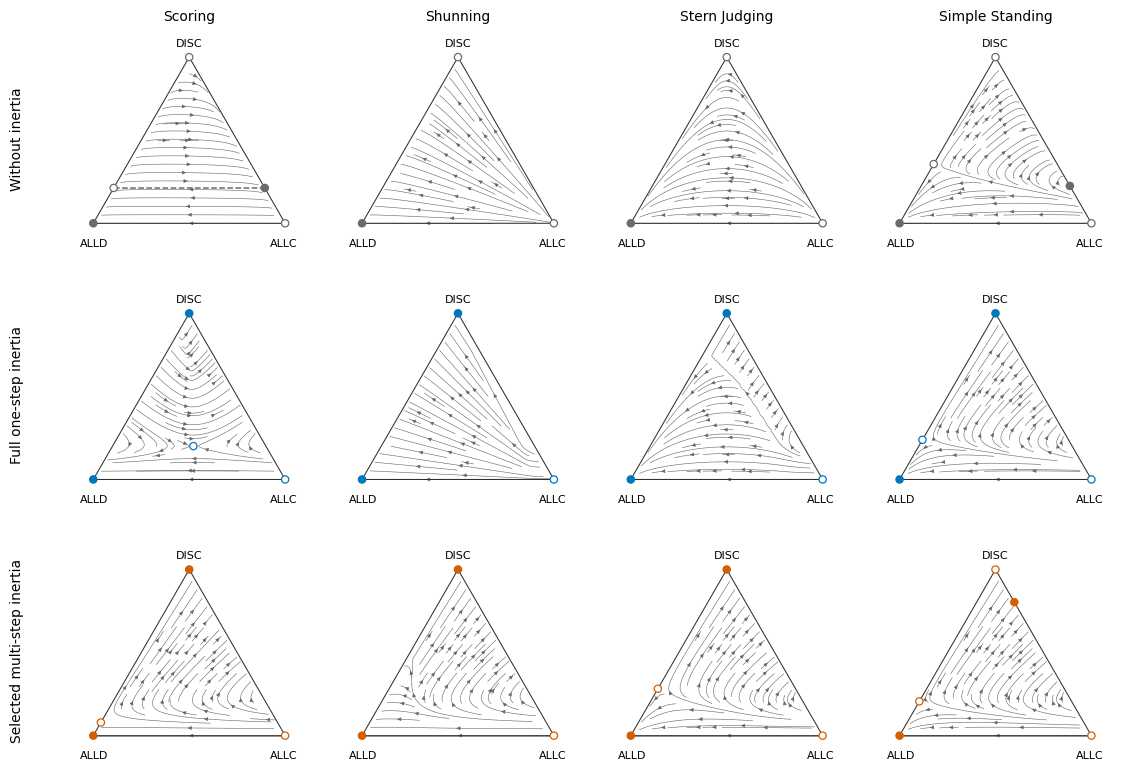

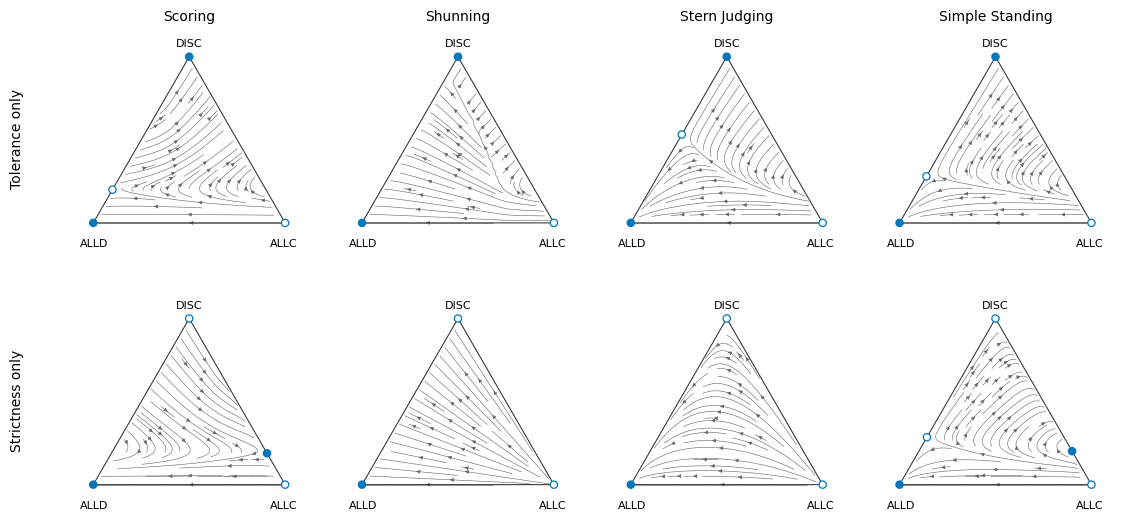

Saved 12 main panels and eight supplementary panels, with two combined figures.


In [5]:
def save_figure(figure, directory, name):
    for extension in ('pdf', 'svg'):
        figure.savefig(directory / f'{name}.{extension}', bbox_inches='tight', pad_inches=.05)


def draw_triangle(axis):
    axis.plot([0, 1, .5, 0], [0, 0, HEIGHT, 0], color=COLOR_BOUNDARY, lw=.75, zorder=6)
    axis.text(.08, -.08, 'ALLD', ha='right', va='top', fontsize=8)
    axis.text(.92, -.08, 'ALLC', ha='left', va='top', fontsize=8)
    axis.text(.5, HEIGHT + .045, 'DISC', ha='center', va='bottom', fontsize=8)
    axis.set(xlim=(-.18, 1.18), ylim=(-.12, HEIGHT + .14), aspect='equal')
    axis.axis('off')


def draw_panel(axis, case):
    par = Parameters(**case['parameters'])
    with np.load(DATA / (case['case'] + '.npz')) as saved:
        x, y, inside, vector = saved['x'], saved['y'], saved['inside'], saved['rhs']
        segment = saved['neutral_segment']
        assert np.max(saved['reputation_residual']) <= SETTINGS.reputation_tolerance
    velocity = simplex_velocity(vector)
    u, v = np.full(inside.shape, np.nan), np.full(inside.shape, np.nan)
    u[inside], v[inside] = velocity.T
    seed_xy = simplex_xy(simplex_lattice(SETTINGS.stream_seed_depth))
    seed_xy[:, 0] = np.clip(seed_xy[:, 0], x[0] + 1e-9, x[-1] - 1e-9)
    seed_xy[:, 1] = np.clip(seed_xy[:, 1], y[0] + 1e-9, y[-1] - 1e-9)
    axis.streamplot(x, y, np.ma.masked_invalid(u), np.ma.masked_invalid(v),
        start_points=seed_xy, color=COLOR_STREAM, linewidth=.42, arrowsize=.55,
        arrowstyle='-|>', minlength=.06, maxlength=2.8, integration_direction='both',
        broken_streamlines=True, zorder=2)
    color = EQUILIBRIUM_COLORS[0 if case['regime'] == 'without_inertia' else
                               2 if case['regime'] == 'multi_step' else 1]
    if len(segment):
        xy = simplex_xy(segment)
        axis.plot(xy[:, 0], xy[:, 1], color=color, lw=1.1, ls='--', zorder=7)
    selected = equilibria_table.loc[equilibria_table.case.eq(case['case'])]
    for row in selected.itertuples():
        xy = simplex_xy(np.array([row.f_ALLC, row.f_ALLD, row.f_DISC]))[0]
        axis.add_patch(Circle(xy, radius=.019, facecolor=color if row.marker_filled else 'white',
                              edgecolor=color, lw=.9, zorder=8))
    draw_triangle(axis)


for case in CASES:
    directory = FIGURE3 if case['regime'] in ('without_inertia', 'one_step', 'multi_step') else ED3
    figure, axis = plt.subplots(figsize=(3.2, 3.0))
    draw_panel(axis, case)
    save_figure(figure, directory, case['case'])
    plt.close(figure)


def combined(regimes, directory, filename):
    figure, axes = plt.subplots(len(regimes), 4, figsize=(11.6, 2.7 * len(regimes)))
    axes = np.atleast_2d(axes)
    figure.subplots_adjust(left=.075, right=.995, bottom=.04, top=.95, hspace=.14, wspace=.03)
    labels = {'without_inertia': 'Without inertia', 'one_step': 'Full one-step inertia',
              'multi_step': 'Selected multi-step inertia', 'tolerance_only': 'Tolerance only',
              'strictness_only': 'Strictness only'}
    for row, regime in enumerate(regimes):
        for column, norm in enumerate(NORMS):
            case = next(c for c in CASES if c['regime'] == regime and c['parameters']['norm'] == norm)
            draw_panel(axes[row, column], case)
            if row == 0:
                axes[row, column].set_title(NORM_NAMES[norm], fontsize=10, pad=7)
            if column == 0:
                axes[row, column].text(-.16, .5, labels[regime], rotation=90,
                    transform=axes[row, column].transAxes, ha='center', va='center', fontsize=10)
    save_figure(figure, directory, filename)
    plt.show()
    plt.close(figure)

combined(('without_inertia', 'one_step', 'multi_step'), FIGURE3, 'Figure3_combined')
combined(('tolerance_only', 'strictness_only'), ED3, 'ED3_simplex_combined')
assert len(list(FIGURE3.glob('*.pdf'))) == len(list(FIGURE3.glob('*.svg'))) == 13
assert len(list(ED3.glob('*.pdf'))) == len(list(ED3.glob('*.svg'))) == 9
print('Saved 12 main panels and eight supplementary panels, with two combined figures.')
